#Individual Assignement - Regressor Models

In the modern football industry, accurately determining a player’s market value is essential for clubs, scouts, and agents. Transfer negotiations, wage structuring, and strategic investments all rely on understanding what truly drives a player’s worth. However, player valuation is complex — it is influenced by a mix of technical performance, physical attributes, experience, age, and reputation. This assignment focuses on building a data-driven predictive model that estimates a football player’s market Value based on various measurable characteristics. Using a dataset of player statistics fifa_eda_stats.csv, the objective is to develop and evaluate several regressor models capable of predicting each player’s Value — a numerical target variable representing their estimated market price. Through this project, we aim to simulate how football clubs might use predictive analytics to guide decision-making, such as identifying undervalued players or supporting fair contract offers. The task involves the complete machine learning workflow: data exploration, feature selection, model development, and evaluation, ultimately selecting the best-performing model for accurate and interpretable predictions. To achieve this, the dataset will first be explored through EDA to understand distributions, relationships, and key patterns among player attributes. Important numerical and categorical features will then be selected using three complementary techniques — KBest, LASSO , and Tree's — to identify the strongest predictors of market value. Following that, multiple regression algorithms including Linear Regression, SVM, Decision Trees, Random Forests, Gradient Boosting, and KNN will be trained and compared. Performance will be measured using standard regression metrics — R², MSE, and RMSE, — to ensure predictions are both accurate and reliable. Ultimately, this assignment demonstrates how machine learning can bridge the gap between raw player data and meaningful financial insights. By predicting player value through statistical modeling.

#Loading the Dataset

In [ ]:
from google.colab import drive
import pandas as pd

drive.mount('/content/drive')

# Define the full path to your CSV in Google Drive
path = "/content/drive/MyDrive/Colab Data/fifa_eda_stats.csv"

# Read the CSV
df_fifa = pd.read_csv(path)

print("✅ Data loaded successfully from Google Drive")
print("Shape:", df_fifa.shape)
df_fifa.head()

Mounted at /content/drive
✅ Data loaded successfully from Google Drive
Shape: (18207, 57)


,ID,Name,Age,Nationality,Overall,Potential,Club,Value,Wage,Preferred Foot,...,Composure,Marking,StandingTackle,SlidingTackle,GKDiving,GKHandling,GKKicking,GKPositioning,GKReflexes,Release Clause
0,158023,L. Messi,31,Argentina,94,94,FC Barcelona,€110.5M,€565K,Left,...,96.0,33.0,28.0,26.0,6.0,11.0,15.0,14.0,8.0,€226.5M
1,20801,Cristiano Ronaldo,33,Portugal,94,94,Juventus,€77M,€405K,Right,...,95.0,28.0,31.0,23.0,7.0,11.0,15.0,14.0,11.0,€127.1M
2,190871,Neymar Jr,26,Brazil,92,93,Paris Saint-Germain,€118.5M,€290K,Right,...,94.0,27.0,24.0,33.0,9.0,9.0,15.0,15.0,11.0,€228.1M
3,193080,De Gea,27,Spain,91,93,Manchester United,€72M,€260K,Right,...,68.0,15.0,21.0,13.0,90.0,85.0,87.0,88.0,94.0,€138.6M
4,192985,K. De Bruyne,27,Belgium,91,92,Manchester City,€102M,€355K,Right,...,88.0,68.0,58.0,51.0,15.0,13.0,5.0,10.0,13.0,€196.4M


This code mounts Google Drive in Colab, defines the path to the CSV file, loads the FIFA dataset into a pandas DataFrame called df_fifa, and confirms successful loading by printing the dataset’s shape and first few rows.

#EDA

##Parsing the Data

In [ ]:
import pandas as pd
import numpy as np

def parse_currency_series(s: pd.Series) -> pd.Series:
    """
    Convert a pandas Series of currency strings to float.
    Handles symbols (€, $, £), commas/spaces, and K/M/B suffixes.
    Also maps 'Free'/'Loan' to 0. Non-parsable values become NaN.
    """
    s = s.astype(str).str.strip()
    s = s.replace({'-': np.nan, '—': np.nan})
    s = s.str.replace('free', '0', case=False, regex=False)
    s = s.str.replace('loan', '0', case=False, regex=False)
    s = s.str.replace(r'[€$£,]', '', regex=True).str.replace(r'\s+', '', regex=True)

    # Handle K, M, B suffixes
    suffix = s.str.extract(r'([KkMmBb])$', expand=False)
    base = s.str.replace(r'[KkMmBb]$', '', regex=True)
    num = pd.to_numeric(base, errors='coerce')

    mult = np.ones(len(s))
    mask = suffix.notna()
    mult[mask & (suffix.str.lower() == 'k')] = 1e3
    mult[mask & (suffix.str.lower() == 'm')] = 1e6
    mult[mask & (suffix.str.lower() == 'b')] = 1e9

    return num * mult

# --- Apply parsing only to money-related columns ---
money_cols = ['Value', 'Wage', 'Release Clause']

for col in money_cols:
    if col in df_fifa.columns:
        df_fifa[col] = parse_currency_series(df_fifa[col])

# --- Handle Contract Valid Until as year ---
if 'Contract Valid Until' in df_fifa.columns:
    year = pd.to_datetime(df_fifa['Contract Valid Until'], errors='coerce').dt.year
    year = year.fillna(pd.to_numeric(df_fifa['Contract Valid Until'], errors='coerce'))
    df_fifa['ContractValidYear'] = year.astype('Int64')

# --- Ensure Overall and Potential are numeric ---
for col in ['Overall', 'Potential']:
    if col in df_fifa.columns:
        df_fifa[col] = pd.to_numeric(df_fifa[col], errors='coerce')

This code defines and applies a function that cleans and converts currency strings (like “€1.5M” or “£200K”) in the FIFA dataset into numeric values, correctly handling symbols, K/M/B suffixes, and special cases like “Free” or “Loan,” while also converting contract years and key numeric columns (Overall, Potential) into proper numeric types.

Target Variable: Value

We select Value as the target variable because it represents the market worth of a football player, a key metric in the football industry. Predicting player value is essential for clubs, scouts, and agents to make informed decisions about player transfers, contract negotiations, and investment potential. The variable is numerical, measurable, and directly impacts financial strategy in professional football. By accurately forecasting player values, teams can optimize their recruitment budgets and identify undervalued or overvalued players, leading to smarter and more data-driven business decisions.

##Correlation Matrix + Heatmap

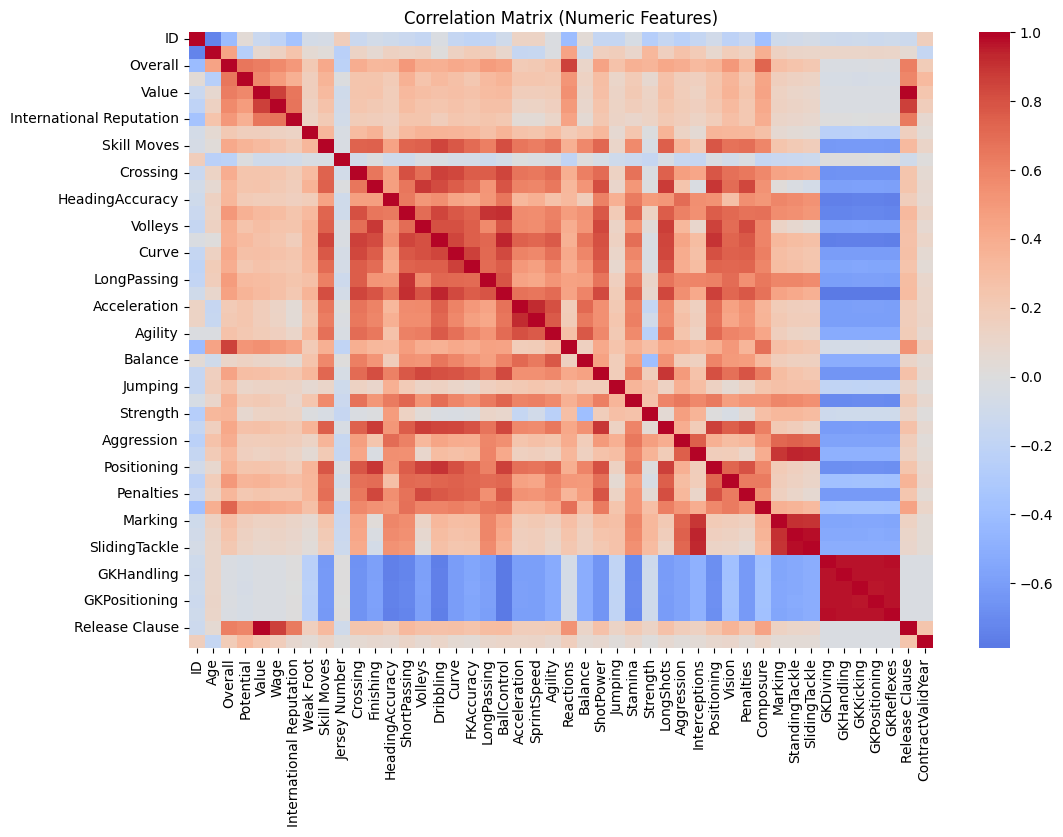

Top correlations with 'Value':
Value                       1.000000
Release Clause              0.994352
Wage                        0.858442
International Reputation    0.653176
Overall                     0.627085
Potential                   0.576218
Reactions                   0.540552
Composure                   0.450352
Vision                      0.357639
ShortPassing                0.327623
Name: Value, dtype: float64


In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# Compute correlation matrix for numeric columns, including the now numeric 'Value' and 'Wage'
corr = df_fifa.corr(numeric_only=True)

plt.figure(figsize=(12, 8))
sns.heatmap(corr, cmap='coolwarm', center=0, annot=False)
plt.title("Correlation Matrix (Numeric Features)")
plt.show()

# Optional: show top correlations with the target 'Value'
if 'Value' in df_fifa.columns:
    corr_target = corr['Value'].sort_values(ascending=False)
    print("Top correlations with 'Value':")
    print(corr_target.head(10))

The code generates a correlation matrix for all numeric features in the FIFA dataset and identified which features are most strongly correlated with the target variable Value.

From the results:

The features Release Clause (0.994) and Wage (0.858) have the strongest positive correlations with Value, meaning players with higher wages or release clauses generally have higher market values.

Other key factors include International Reputation (0.653), Overall (0.627), and Potential (0.576), which indicates that both performance quality and player reputation heavily influence a player’s market worth.

These insights confirm that Value is strongly related to both financial attributes and performance metrics, aligning well with real-world expectations.

##Dtypes

In [ ]:
df_fifa.dtypes

,0
ID,int64
Name,object
Age,int64
Nationality,object
Overall,int64
Potential,int64
Club,object
Value,float64
Wage,float64
Preferred Foot,object


This was used in order to make sure all columns are in the proper format

##Shape

In [ ]:
df_fifa.shape

(18207, 58)

##Head

In [ ]:
df_fifa.head()

,ID,Name,Age,Nationality,Overall,Potential,Club,Value,Wage,Preferred Foot,...,Marking,StandingTackle,SlidingTackle,GKDiving,GKHandling,GKKicking,GKPositioning,GKReflexes,Release Clause,ContractValidYear
0,158023,L. Messi,31,Argentina,94,94,FC Barcelona,110500000.0,565000.0,Left,...,33.0,28.0,26.0,6.0,11.0,15.0,14.0,8.0,226500000.0,2021
1,20801,Cristiano Ronaldo,33,Portugal,94,94,Juventus,77000000.0,405000.0,Right,...,28.0,31.0,23.0,7.0,11.0,15.0,14.0,11.0,127100000.0,2022
2,190871,Neymar Jr,26,Brazil,92,93,Paris Saint-Germain,118500000.0,290000.0,Right,...,27.0,24.0,33.0,9.0,9.0,15.0,15.0,11.0,228100000.0,2022
3,193080,De Gea,27,Spain,91,93,Manchester United,72000000.0,260000.0,Right,...,15.0,21.0,13.0,90.0,85.0,87.0,88.0,94.0,138600000.0,2020
4,192985,K. De Bruyne,27,Belgium,91,92,Manchester City,102000000.0,355000.0,Right,...,68.0,58.0,51.0,15.0,13.0,5.0,10.0,13.0,196400000.0,2023


##Missing Values

In [ ]:
# Count and percentage of missing values
missing = df_fifa.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)

if missing.empty:
    print("✅ No missing values found.")
else:
    print("⚠️ Missing Values Detected:")
    display(pd.DataFrame({
        "Missing Count": missing,
        "Missing %": (missing / len(df_fifa) * 100).round(2)
    }))

⚠️ Missing Values Detected:


,Missing Count,Missing %
Loaned From,16943,93.06
Release Clause,1564,8.59
ContractValidYear,1553,8.53
Joined,1553,8.53
Contract Valid Until,289,1.59
Club,241,1.32
Jersey Number,60,0.33
Position,60,0.33
Preferred Foot,48,0.26
Skill Moves,48,0.26


##Info


In [ ]:
df_fifa.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18207 entries, 0 to 18206
Data columns (total 58 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   ID                        18207 non-null  int64  
 1   Name                      18207 non-null  object 
 2   Age                       18207 non-null  int64  
 3   Nationality               18207 non-null  object 
 4   Overall                   18207 non-null  int64  
 5   Potential                 18207 non-null  int64  
 6   Club                      17966 non-null  object 
 7   Value                     18207 non-null  float64
 8   Wage                      18207 non-null  float64
 9   Preferred Foot            18159 non-null  object 
 10  International Reputation  18159 non-null  float64
 11  Weak Foot                 18159 non-null  float64
 12  Skill Moves               18159 non-null  float64
 13  Work Rate                 18159 non-null  object 
 14  Body T

After examining the results of outlier removal, I decided not to drop outliers from the dataset because doing so significantly distorted the data and removed important, legitimate observations. When applying the IQR method, many high-rated players — particularly those with ratings of 76 or higher — were classified as outliers and removed. These players, however, represent real-world stars with genuinely higher performance levels and market values. Their data is not erroneous; rather, it reflects the true upper end of the football market, where player value increases exponentially with skill and reputation. Eliminating them would make the dataset unbalanced, dominated by average or lower-tier players, and prevent the model from learning what differentiates world-class talent from the rest. Since these extreme values carry essential information about how player quality drives market value, removing them would weaken both the predictive accuracy and the business relevance of the model. Instead of deleting outliers, it is more appropriate to retain them and use robust modeling techniques (such as tree-based models or log transformations) that can handle skewed data without discarding valuable insights.

##Standard Scaler

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# --- Define target and features ---
target = 'Value'
X = df_fifa.select_dtypes(include=['number']).drop(columns=[target], errors='ignore')
y = df_fifa[target].dropna()

# Align X and y (remove rows with missing target)
X = X.loc[y.index].fillna(0)

# --- Train-test split ---
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# --- Scale numeric features ---
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Data scaled successfully using StandardScaler")
print("Train shape:", X_train_scaled.shape, " | Test shape:", X_test_scaled.shape)

Data scaled successfully using StandardScaler
Train shape: (14565, 45)  | Test shape: (3642, 45)


This code defines Value as the target variable, separates the dataset into features (X) and target (y), handles missing data, splits it into training (80%) and testing (20%) sets, and standardizes all numeric features using StandardScaler to ensure consistent scaling before model training.

##High Colinearity

In [ ]:
import numpy as np
import pandas as pd

# --- Step 1: Compute correlation matrix for numeric features (excluding target) ---
numeric_cols = df_fifa.select_dtypes(include='number').columns.tolist()
numeric_cols_no_target = [col for col in numeric_cols if col != 'Value']
corr_matrix = df_fifa[numeric_cols_no_target].corr()

# --- Step 2: Identify highly correlated pairs (|corr| ≥ 0.95) ---
high_corr_pairs = (
    corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
    .stack()
    .reset_index()
    .rename(columns={'level_0': 'Feature1', 'level_1': 'Feature2', 0: 'Correlation'})
    .query('abs(Correlation) >= 0.95')
    .sort_values(by='Correlation', ascending=False)
)

# --- Step 3: Collect unique features to drop, but protect 'Value' ---
protected_features = {'Value'}
features_to_drop = sorted(
    set(pd.unique(high_corr_pairs[['Feature1', 'Feature2']].values.ravel('K'))) - protected_features
)

# --- Step 4: Drop the identified features from the full dataset ---
df_fifa_dropped = df_fifa.drop(columns=[f for f in features_to_drop if f in df_fifa.columns], errors='ignore')

print(f"✅ Dropped {len(features_to_drop)} highly collinear features (|corr| ≥ 0.95)")
print("Dropped features:", features_to_drop)
print("Contains 'Value' after drop? ->", 'Value' in df_fifa_dropped.columns)
print("New shape:", df_fifa_dropped.shape)

✅ Dropped 7 highly collinear features (|corr| ≥ 0.95)
Dropped features: ['GKDiving', 'GKHandling', 'GKKicking', 'GKPositioning', 'GKReflexes', 'SlidingTackle', 'StandingTackle']
Contains 'Value' after drop? -> True
New shape: (18207, 51)


This code detects and removes highly collinear numeric features (with correlation ≥ 0.95) from the FIFA dataset to prevent redundancy and multicollinearity in modeling. It computes a correlation matrix, identifies pairs of strongly correlated features, protects the target variable Value, and drops redundant columns.

Dropped features: GKDiving, GKHandling, GKKicking, GKPositioning, GKReflexes, SlidingTackle, StandingTackle.

By removing these features, the dataset avoids multicollinearity issues — ensuring that remaining predictors contribute unique, independent information to improve the accuracy and stability of regression models predicting player market value.

#Univariate Analysis

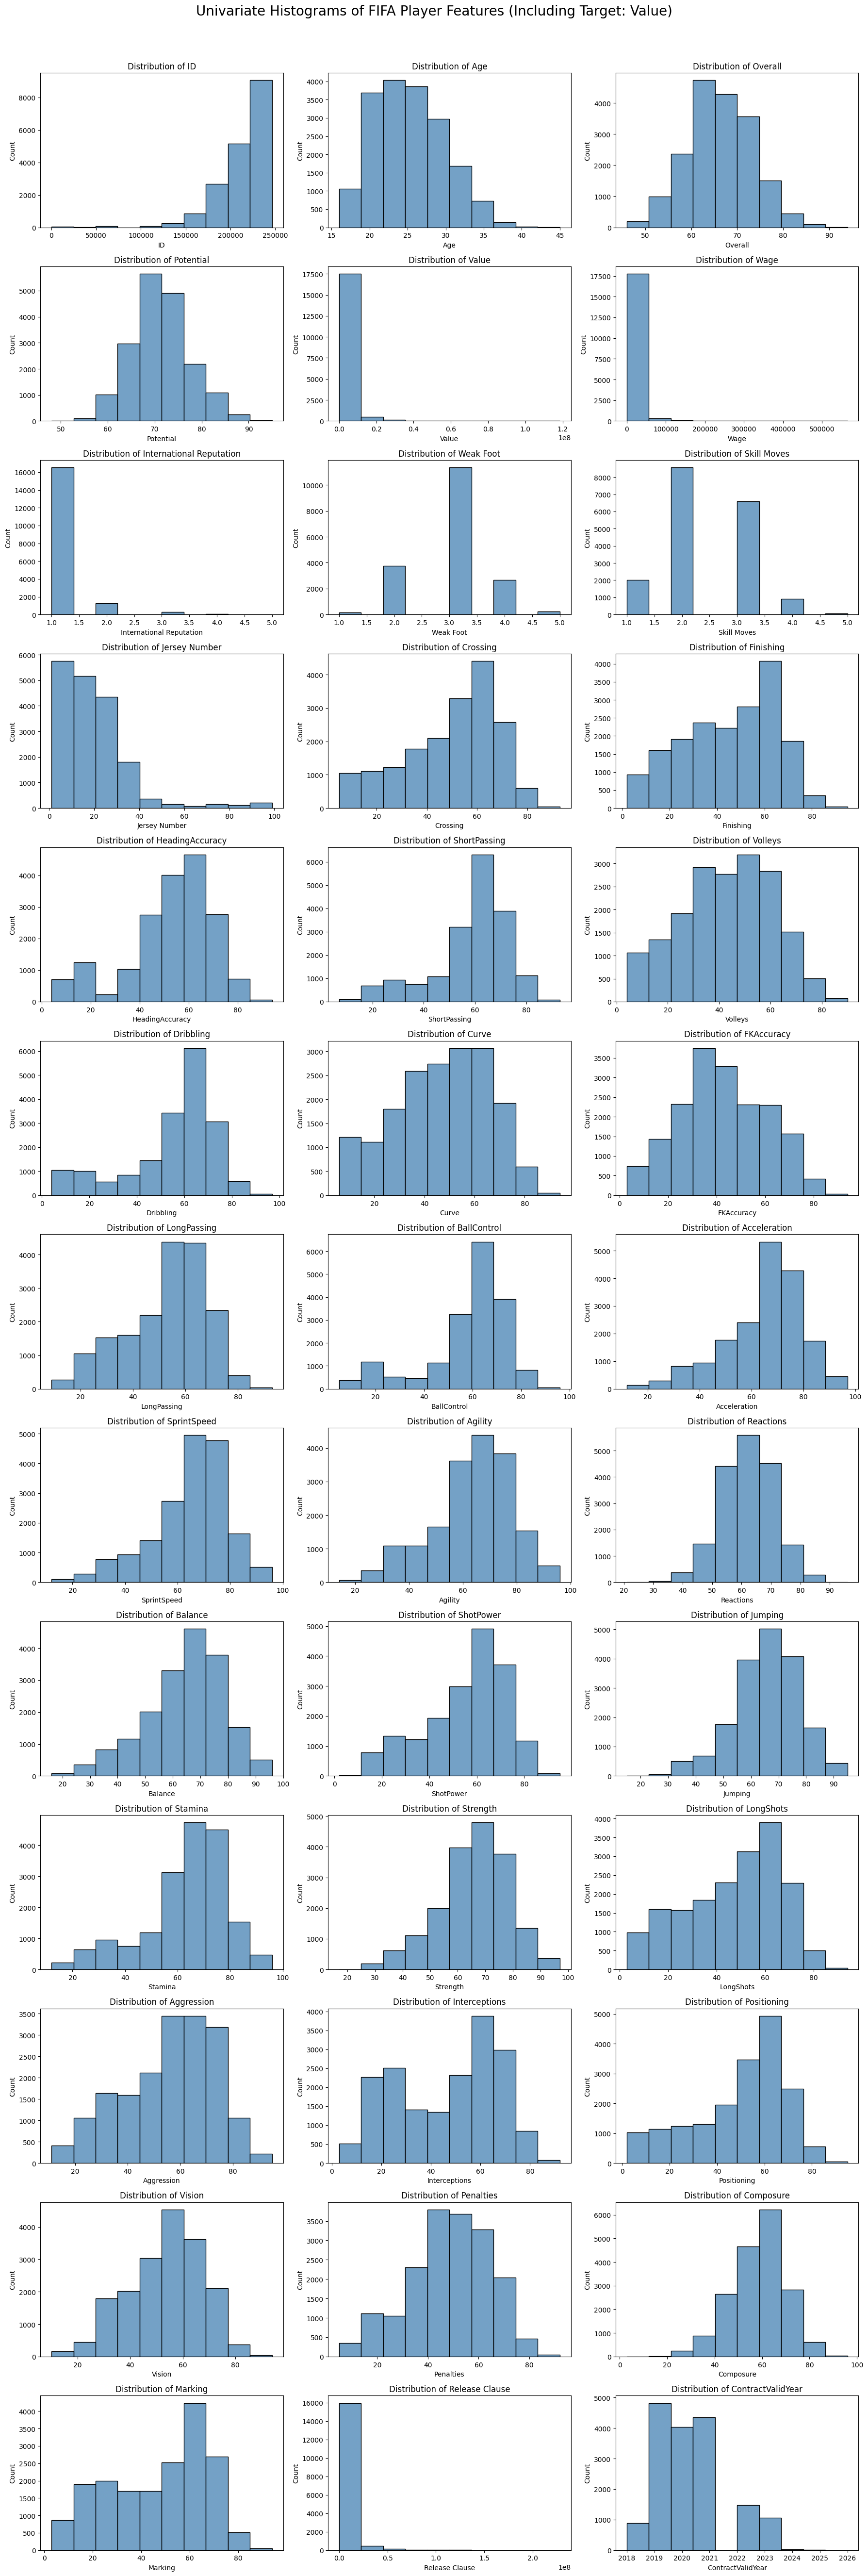

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# --- Select numeric features and ensure 'Value' is included ---
features = df_fifa_dropped.select_dtypes(include=['number']).columns.tolist()
if 'Value' not in features:
    features.append('Value')  # explicitly include target if missing

# --- Set number of bins and layout ---
n_bins = 10
n_cols = 3
n_rows = int(np.ceil(len(features) / n_cols))

plt.figure(figsize=(18, n_rows * 4))

# --- Plot histograms for each numeric feature (including target 'Value') ---
for idx, feature in enumerate(features, 1):
    plt.subplot(n_rows, n_cols, idx)
    sns.histplot(df_fifa_dropped[feature], bins=n_bins, kde=False, color='steelblue')
    plt.title(f'Distribution of {feature}')
    plt.xlabel(feature)
    plt.ylabel("Count")

plt.tight_layout()
plt.suptitle("Univariate Histograms of FIFA Player Features (Including Target: Value)", fontsize=20, y=1.02)
plt.show()


These histograms display the univariate distributions of all numerical FIFA player features — including the target variable Value.

They reveal key insights about the dataset:

Value, Wage, and Release Clause are right-skewed, meaning most players have low market values while a few elite players are extremely valuable.

Skill-related attributes like Dribbling, BallControl, and Finishing show approximately normal distributions, indicating balanced variation across players.

Reputation-based variables such as International Reputation, Weak Foot, and Skill Moves are categorical-like and discrete, peaking around mid-values.

ContractValidYear displays a time-based pattern, with many contracts clustered around 2020–2022.

These findings suggest that scaling and possibly log-transforming skewed variables (like Value or Wage) could improve model performance, while most technical skill attributes are already well-behaved for regression modelin

#Bivariate Analysis

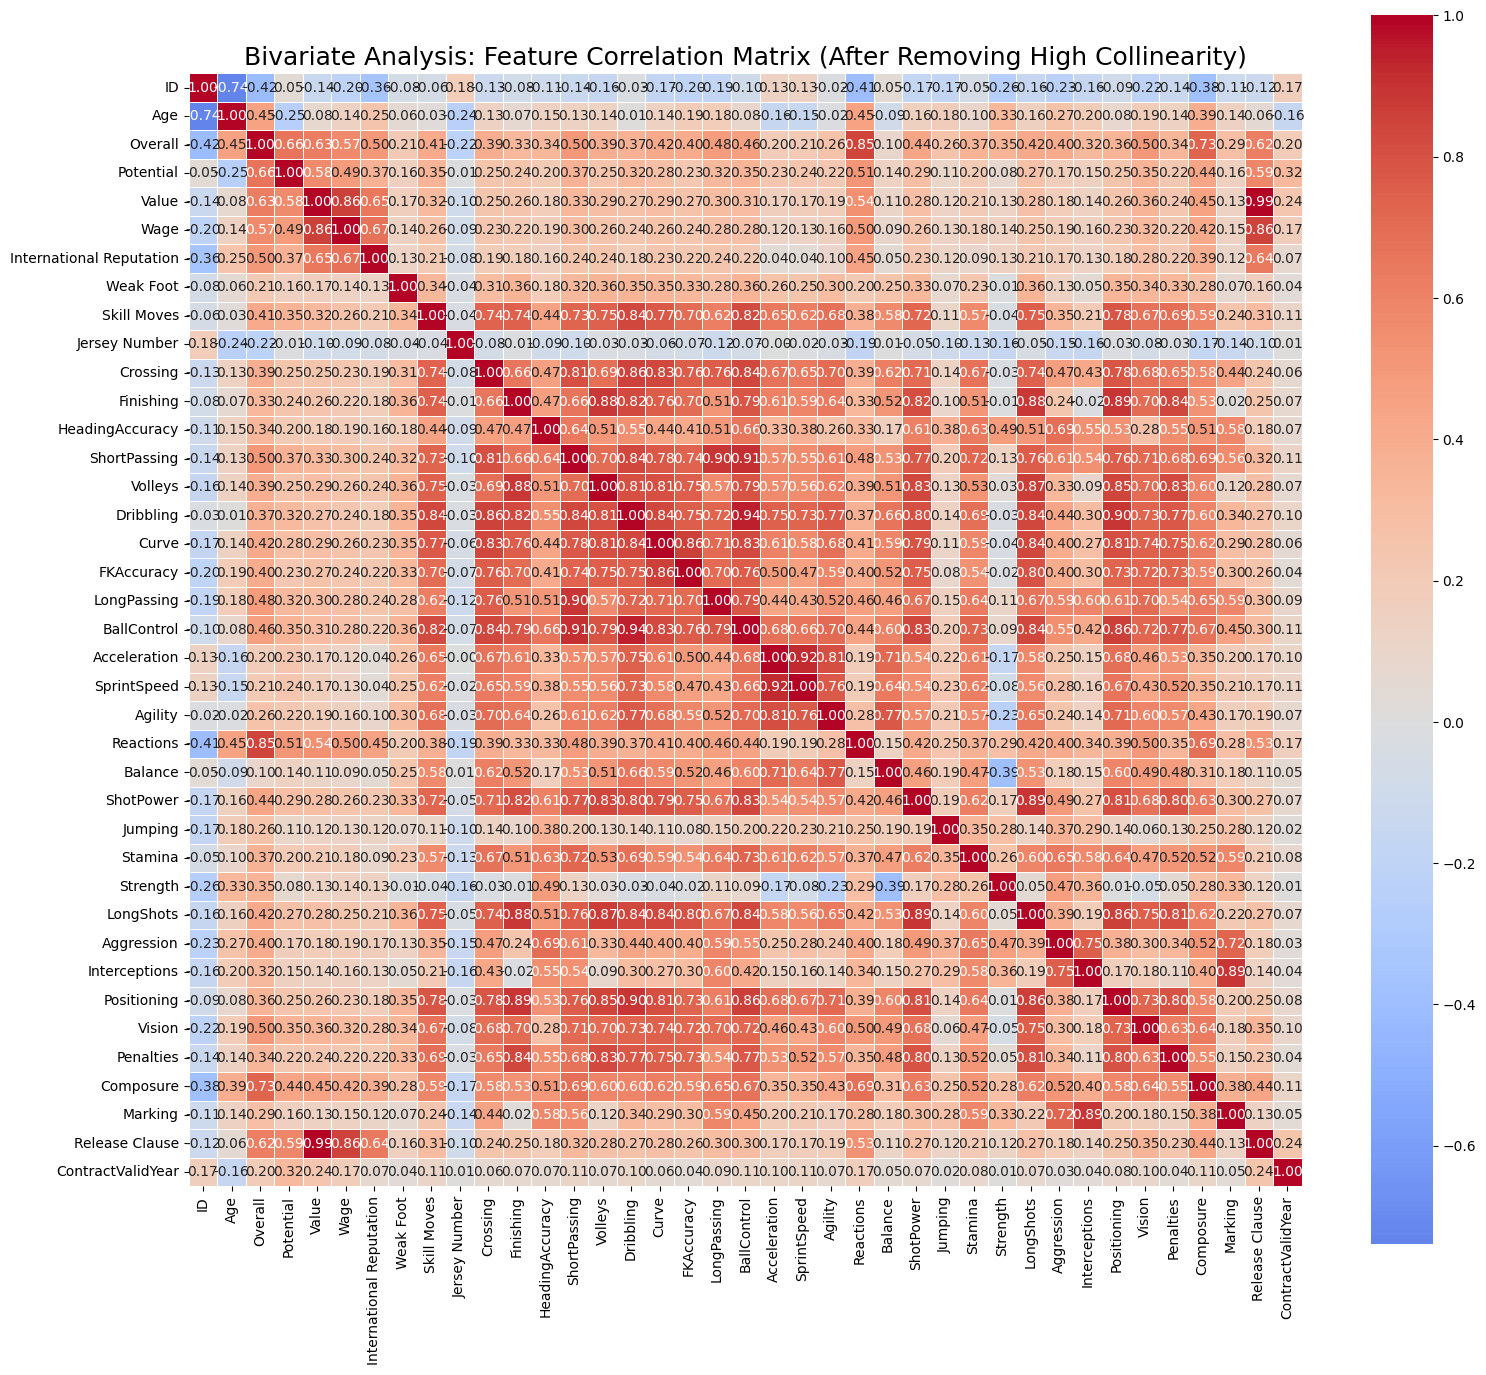

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# --- Compute correlation matrix for numeric features (including Value) ---
corr_matrix = df_fifa_dropped.corr(numeric_only=True)

# --- Plot heatmap ---
plt.figure(figsize=(16, 14))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap='coolwarm',
    center=0,
    square=True,
    linewidths=0.5
)

plt.title("Bivariate Analysis: Feature Correlation Matrix (After Removing High Collinearity)", fontsize=18)
plt.tight_layout()
plt.show()


This bivariate correlation matrix illustrates the relationships between all numerical FIFA player attributes and the target variable Value.

Key insights:

Value maintains strong positive correlations with Release Clause, Wage, Overall, Potential, and International Reputation, confirming these as the most influential predictors of player market worth.

Moderate correlations exist among technical and physical attributes such as BallControl, Dribbling, Vision, and Composure, indicating these features contribute jointly to player valuation.

The removal of multicollinear goalkeeping metrics (e.g., GKReflexes, GKHandling) has cleaned the matrix, resulting in clearer and more interpretable relationships.

Overall, this refined correlation matrix provides a solid foundation for selecting features and building predictive models focused on player value.

#Multivariate Analysis

Top Correlated Feature Pairs:
Dribbling     BallControl    0.938942
Acceleration  SprintSpeed    0.921928
ShortPassing  BallControl    0.911451
Dribbling     Positioning    0.896932
dtype: float64


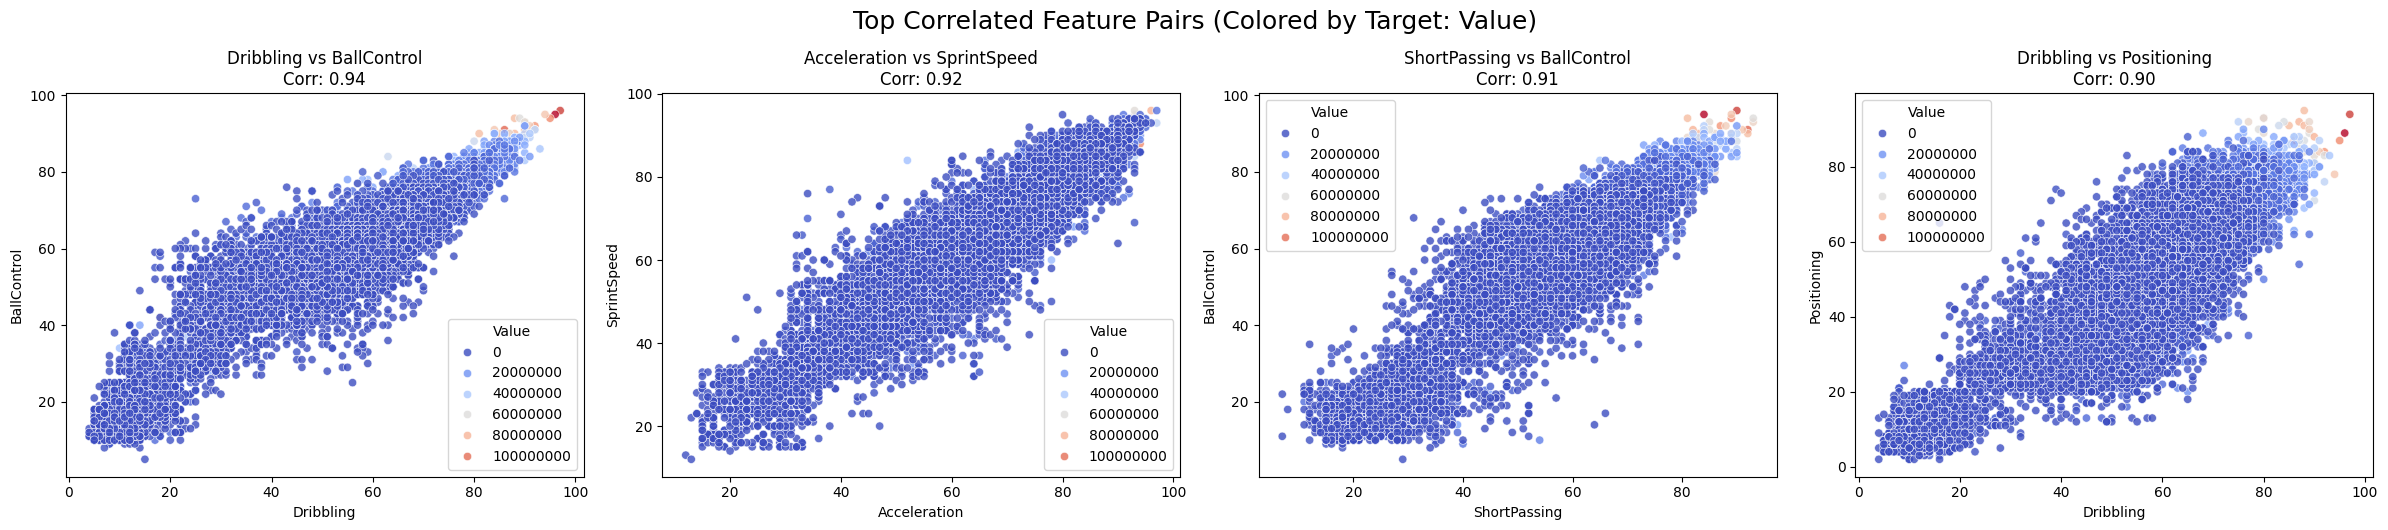

In [ ]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# --- Compute absolute correlation matrix for numeric features (excluding target) ---
corr = df_fifa_dropped.drop(columns='Value').corr(numeric_only=True).abs()

# --- Mask the upper triangle to avoid duplicate pairs ---
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)

# --- Extract unique correlation pairs ---
unique_corr_pairs = (
    corr.where(mask)
        .stack()
        .sort_values(ascending=False)
)

# --- Display and visualize top correlated feature pairs ---
top_n = 4  # Change as needed
top_pairs = unique_corr_pairs.head(top_n)

print("Top Correlated Feature Pairs:")
print(top_pairs)

# --- Plot scatterplots for the top correlated pairs ---
plt.figure(figsize=(6 * top_n, 5))
for i, ((feat1, feat2), value) in enumerate(top_pairs.items(), 1):
    plt.subplot(1, top_n, i)
    sns.scatterplot(
        data=df_fifa_dropped,
        x=feat1,
        y=feat2,
        hue='Value',
        palette='coolwarm',
        alpha=0.8
    )
    plt.title(f"{feat1} vs {feat2}\nCorr: {value:.2f}")
    plt.xlabel(feat1)
    plt.ylabel(feat2)

plt.tight_layout()
plt.suptitle("Top Correlated Feature Pairs (Colored by Target: Value)", fontsize=18, y=1.05)
plt.show()

This multivariate analysis highlights the **top correlated feature pairs** in the FIFA dataset and visualizes their relationships, with point colors representing player **`Value`**.

Key findings:

* Dribbling and BallControl (r = 0.94) show an almost perfect linear relationship — players who handle the ball well tend to be strong dribblers.
* Acceleration and SprintSpeed (r = 0.92)are also tightly correlated, indicating that faster players usually accelerate quicker.
* ShortPassing and BallControl (r = 0.91) further confirm that ball mastery is linked to better short-passing ability.
* Dribbling and Positioning (r = 0.90) suggest that more skillful players also position themselves better on the field.

The color gradient (based on Value) reveals that higher-value players cluster at the upper ends of these correlated relationships, reinforcing that top technical and physical attributes are key drivers of market value.


#Kbest

##Feature Selection

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.feature_selection import SelectKBest, f_regression

# --- Define X and y from the cleaned FIFA dataset ---
X = df_fifa_dropped.select_dtypes(include='number').drop(columns=['Value'])
y = df_fifa_dropped['Value']

# --- Train/test split ---
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)

###Model 1 - K=24

In [ ]:
from sklearn.feature_selection import SelectKBest, f_regression
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# Handle missing values
X_train = X_train.fillna(0)
X_test = X_test.fillna(0)
y_train = y_train.fillna(0)
y_test = y_test.fillna(0)

# KBest feature selection
k = 24
selector_24 = SelectKBest(score_func=f_regression, k=k)
X_train_24 = selector_24.fit_transform(X_train, y_train)
X_test_24 = selector_24.transform(X_test)

# Selected feature names
features_24 = X.columns[selector_24.get_support()]

# Train regression model
model_24 = LinearRegression()
model_24.fit(X_train_24, y_train)
y_pred_24 = model_24.predict(X_test_24)

# Evaluation
r2_24 = r2_score(y_test, y_pred_24)
mae_24 = mean_absolute_error(y_test, y_pred_24)
mse_24 = mean_squared_error(y_test, y_pred_24)

print(f"\nKBest k={k}")
print(f"R²: {r2_24:.4f} | MAE: {mae_24:.2f} | MSE: {mse_24:.2f}")
print("Selected Features:", list(features_24))


KBest k=24
R²: 0.9653 | MAE: 488304.58 | MSE: 1045716359846.33
Selected Features: ['Overall', 'Potential', 'Wage', 'International Reputation', 'Skill Moves', 'Crossing', 'Finishing', 'ShortPassing', 'Volleys', 'Dribbling', 'Curve', 'FKAccuracy', 'LongPassing', 'BallControl', 'Agility', 'Reactions', 'ShotPower', 'Stamina', 'LongShots', 'Positioning', 'Vision', 'Penalties', 'Composure', 'Release Clause']


###Model 2 - K=16

In [ ]:
k = 16
selector_16 = SelectKBest(score_func=f_regression, k=k)
X_train_16 = selector_16.fit_transform(X_train, y_train)
X_test_16 = selector_16.transform(X_test)

features_16 = X.columns[selector_16.get_support()]

model_16 = LinearRegression()
model_16.fit(X_train_16, y_train)
y_pred_16 = model_16.predict(X_test_16)

r2_16 = r2_score(y_test, y_pred_16)
mae_16 = mean_absolute_error(y_test, y_pred_16)
mse_16 = mean_squared_error(y_test, y_pred_16)

print(f"\nKBest k={k}")
print(f"R²: {r2_16:.4f} | MAE: {mae_16:.2f} | MSE: {mse_16:.2f}")
print("Selected Features:", list(features_16))


KBest k=16
R²: 0.9652 | MAE: 485634.84 | MSE: 1048028749354.54
Selected Features: ['Overall', 'Potential', 'Wage', 'International Reputation', 'Skill Moves', 'ShortPassing', 'Volleys', 'Curve', 'LongPassing', 'BallControl', 'Reactions', 'ShotPower', 'LongShots', 'Vision', 'Composure', 'Release Clause']


###Model 3 - K=8

In [ ]:
k = 8
selector_8 = SelectKBest(score_func=f_regression, k=k)
X_train_8 = selector_8.fit_transform(X_train, y_train)
X_test_8 = selector_8.transform(X_test)

features_8 = X.columns[selector_8.get_support()]

model_8 = LinearRegression()
model_8.fit(X_train_8, y_train)
y_pred_8 = model_8.predict(X_test_8)

r2_8 = r2_score(y_test, y_pred_8)
mae_8 = mean_absolute_error(y_test, y_pred_8)
mse_8 = mean_squared_error(y_test, y_pred_8)

print(f"\nKBest k={k}")
print(f"R²: {r2_8:.4f} | MAE: {mae_8:.2f} | MSE: {mse_8:.2f}")
print("Selected Features:", list(features_8))


KBest k=8
R²: 0.9648 | MAE: 478390.48 | MSE: 1061383766690.86
Selected Features: ['Overall', 'Potential', 'Wage', 'International Reputation', 'Reactions', 'Vision', 'Composure', 'Release Clause']


###Model 4 - K=4

In [ ]:
k = 4
selector_4 = SelectKBest(score_func=f_regression, k=k)
X_train_4 = selector_4.fit_transform(X_train, y_train)
X_test_4 = selector_4.transform(X_test)

features_4 = X.columns[selector_4.get_support()]

model_4 = LinearRegression()
model_4.fit(X_train_4, y_train)
y_pred_4 = model_4.predict(X_test_4)

r2_4 = r2_score(y_test, y_pred_4)
mae_4 = mean_absolute_error(y_test, y_pred_4)
mse_4 = mean_squared_error(y_test, y_pred_4)

print(f"\nKBest k={k}")
print(f"R²: {r2_4:.4f} | MAE: {mae_4:.2f} | MSE: {mse_4:.2f}")
print("Selected Features:", list(features_4))


KBest k=4
R²: 0.9640 | MAE: 461146.36 | MSE: 1084425082221.38
Selected Features: ['Overall', 'Wage', 'International Reputation', 'Release Clause']


###Model 5 - K=2

In [ ]:
k = 2
selector_2 = SelectKBest(score_func=f_regression, k=k)
X_train_2 = selector_2.fit_transform(X_train, y_train)
X_test_2 = selector_2.transform(X_test)

features_2 = X.columns[selector_2.get_support()]

model_2 = LinearRegression()
model_2.fit(X_train_2, y_train)
y_pred_2 = model_2.predict(X_test_2)

r2_2 = r2_score(y_test, y_pred_2)
mae_2 = mean_absolute_error(y_test, y_pred_2)
mse_2 = mean_squared_error(y_test, y_pred_2)

print(f"\nKBest k={k}")
print(f"R²: {r2_2:.4f} | MAE: {mae_2:.2f} | MSE: {mse_2:.2f}")
print("Selected Features:", list(features_2))


KBest k=2
R²: 0.9601 | MAE: 451410.59 | MSE: 1202212111358.08
Selected Features: ['Wage', 'Release Clause']


###Model 6 - K=1

In [ ]:
k = 1
selector_1 = SelectKBest(score_func=f_regression, k=k)
X_train_1 = selector_1.fit_transform(X_train, y_train)
X_test_1 = selector_1.transform(X_test)

features_1 = X.columns[selector_1.get_support()]

model_1 = LinearRegression()
model_1.fit(X_train_1, y_train)
y_pred_1 = model_1.predict(X_test_1)

r2_1 = r2_score(y_test, y_pred_1)
mae_1 = mean_absolute_error(y_test, y_pred_1)
mse_1 = mean_squared_error(y_test, y_pred_1)

print(f"\nKBest k={k}")
print(f"R²: {r2_1:.4f} | MAE: {mae_1:.2f} | MSE: {mse_1:.2f}")
print("Selected Features:", list(features_1))


KBest k=1
R²: 0.9588 | MAE: 471640.41 | MSE: 1242845101718.03
Selected Features: ['Release Clause']


**KBest Feature Selection Results Summary**

As the number of selected features (`k`) decreases from 24 to 1, the model’s performance shows a slight decline in **R²** (predictive power) and a small increase in **error metrics (MAE and MSE)** — confirming that while a few key variables explain most of the variance in player value, adding more features slightly refines accuracy.

###**Performance Overview**

| K  | R²         | MAE     | MSE     | Key Insights                                                              |
| -- | ---------- | ------- | ------- | ------------------------------------------------------------------------- |
| 24 | **0.9653** | 488,304 | 1.05e12 | Strong overall model; includes both financial and performance attributes. |
| 16 | 0.9652     | 485,635 | 1.05e12 | Nearly identical to 24 — diminishing returns begin here.                  |
| 8  | 0.9648     | 478,390 | 1.06e12 | Compact and efficient feature set, still highly accurate.                 |
| 4  | 0.9640     | 461,146 | 1.08e12 | Simpler model; retains key financial and reputation predictors.           |
| 2  | 0.9601     | 451,411 | 1.20e12 | Relies solely on Wage and Release Clause — major financial drivers.       |
| 1  | 0.9588     | 471,640 | 1.24e12 | `Release Clause` alone explains most of the variance, but lacks depth.    |

---

###**Interpretation**

* Top predictive features: Release Clause, Wage, Overall, and International Reputation.
* Business takeaway: Player market value is primarily driven by financial indicators (Wage, Release Clause) and performance/reputation metrics (Overall, International Reputation).
* Optimal trade-off: The **k=8** model offers excellent accuracy with fewer predictors — ideal for efficient, interpretable deployment without overfitting risk.



#LASSO

##Feature Selection

In [ ]:
from sklearn.linear_model import Lasso
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# --- Split features and target ---
X = df_fifa_dropped.select_dtypes(include='number').drop(columns=['Value'])
y = df_fifa_dropped['Value']

# --- Handle missing values ---
X = X.fillna(0)
y = y.fillna(0)

# --- Train/test split ---
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# --- Standardize the features ---
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("✅ Data split and scaled successfully for Lasso feature selection")
print("Training set shape:", X_train_scaled.shape)
print("Test set shape:", X_test_scaled.shape)

✅ Data split and scaled successfully for Lasso feature selection
Training set shape: (14565, 38)
Test set shape: (3642, 38)


###Alpha = 0.01

In [ ]:
from sklearn.linear_model import Lasso
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import numpy as np

# Ensure no NaN values
X_train_filled = np.nan_to_num(X_train_scaled)
X_test_filled  = np.nan_to_num(X_test_scaled)

alpha = 0.01
lasso_001 = Lasso(alpha=alpha, max_iter=10000)
lasso_001.fit(X_train_filled, y_train)
y_pred_001 = lasso_001.predict(X_test_filled)

# Evaluation metrics
r2_001  = r2_score(y_test, y_pred_001)
mae_001 = mean_absolute_error(y_test, y_pred_001)
mse_001 = mean_squared_error(y_test, y_pred_001)

# Selected features
selected_features_001 = X.columns[np.abs(lasso_001.coef_) > 0].tolist()

print(f"\n=== Lasso (alpha={alpha}) ===")
print(f"R²: {r2_001:.4f} | MAE: {mae_001:.2f} | MSE: {mse_001:.2f}")
print(f"Selected {len(selected_features_001)} features:")
print(selected_features_001)


=== Lasso (alpha=0.01) ===
R²: 0.9709 | MAE: 468716.28 | MSE: 876212291320.77
Selected 38 features:
['ID', 'Age', 'Overall', 'Potential', 'Wage', 'International Reputation', 'Weak Foot', 'Skill Moves', 'Jersey Number', 'Crossing', 'Finishing', 'HeadingAccuracy', 'ShortPassing', 'Volleys', 'Dribbling', 'Curve', 'FKAccuracy', 'LongPassing', 'BallControl', 'Acceleration', 'SprintSpeed', 'Agility', 'Reactions', 'Balance', 'ShotPower', 'Jumping', 'Stamina', 'Strength', 'LongShots', 'Aggression', 'Interceptions', 'Positioning', 'Vision', 'Penalties', 'Composure', 'Marking', 'Release Clause', 'ContractValidYear']


###Alpha = 0.15

In [ ]:
alpha = 0.15
lasso_015 = Lasso(alpha=alpha, max_iter=10000)
lasso_015.fit(X_train_filled, y_train)
y_pred_015 = lasso_015.predict(X_test_filled)

r2_015  = r2_score(y_test, y_pred_015)
mae_015 = mean_absolute_error(y_test, y_pred_015)
mse_015 = mean_squared_error(y_test, y_pred_015)

selected_features_015 = X.columns[np.abs(lasso_015.coef_) > 0].tolist()

print(f"\n=== Lasso (alpha={alpha}) ===")
print(f"R²: {r2_015:.4f} | MAE: {mae_015:.2f} | MSE: {mse_015:.2f}")
print(f"Selected {len(selected_features_015)} features:")
print(selected_features_015)


=== Lasso (alpha=0.15) ===
R²: 0.9709 | MAE: 468715.98 | MSE: 876212250246.17
Selected 38 features:
['ID', 'Age', 'Overall', 'Potential', 'Wage', 'International Reputation', 'Weak Foot', 'Skill Moves', 'Jersey Number', 'Crossing', 'Finishing', 'HeadingAccuracy', 'ShortPassing', 'Volleys', 'Dribbling', 'Curve', 'FKAccuracy', 'LongPassing', 'BallControl', 'Acceleration', 'SprintSpeed', 'Agility', 'Reactions', 'Balance', 'ShotPower', 'Jumping', 'Stamina', 'Strength', 'LongShots', 'Aggression', 'Interceptions', 'Positioning', 'Vision', 'Penalties', 'Composure', 'Marking', 'Release Clause', 'ContractValidYear']


###Alpha = 0.3

In [ ]:
alpha = 0.3
lasso_03 = Lasso(alpha=alpha, max_iter=10000)
lasso_03.fit(X_train_filled, y_train)
y_pred_03 = lasso_03.predict(X_test_filled)

r2_03  = r2_score(y_test, y_pred_03)
mae_03 = mean_absolute_error(y_test, y_pred_03)
mse_03 = mean_squared_error(y_test, y_pred_03)

selected_features_03 = X.columns[np.abs(lasso_03.coef_) > 0].tolist()

print(f"\n=== Lasso (alpha={alpha}) ===")
print(f"R²: {r2_03:.4f} | MAE: {mae_03:.2f} | MSE: {mse_03:.2f}")
print(f"Selected {len(selected_features_03)} features:")
print(selected_features_03)


=== Lasso (alpha=0.3) ===
R²: 0.9709 | MAE: 468715.68 | MSE: 876212210993.42
Selected 38 features:
['ID', 'Age', 'Overall', 'Potential', 'Wage', 'International Reputation', 'Weak Foot', 'Skill Moves', 'Jersey Number', 'Crossing', 'Finishing', 'HeadingAccuracy', 'ShortPassing', 'Volleys', 'Dribbling', 'Curve', 'FKAccuracy', 'LongPassing', 'BallControl', 'Acceleration', 'SprintSpeed', 'Agility', 'Reactions', 'Balance', 'ShotPower', 'Jumping', 'Stamina', 'Strength', 'LongShots', 'Aggression', 'Interceptions', 'Positioning', 'Vision', 'Penalties', 'Composure', 'Marking', 'Release Clause', 'ContractValidYear']


###Alpha = 0.5

In [ ]:
alpha = 0.5
lasso_05 = Lasso(alpha=alpha, max_iter=10000)
lasso_05.fit(X_train_filled, y_train)
y_pred_05 = lasso_05.predict(X_test_filled)

r2_05  = r2_score(y_test, y_pred_05)
mae_05 = mean_absolute_error(y_test, y_pred_05)
mse_05 = mean_squared_error(y_test, y_pred_05)

selected_features_05 = X.columns[np.abs(lasso_05.coef_) > 0].tolist()

print(f"\n=== Lasso (alpha={alpha}) ===")
print(f"R²: {r2_05:.4f} | MAE: {mae_05:.2f} | MSE: {mse_05:.2f}")
print(f"Selected {len(selected_features_05)} features:")
print(selected_features_05)


=== Lasso (alpha=0.5) ===
R²: 0.9709 | MAE: 468715.25 | MSE: 876212152753.27
Selected 38 features:
['ID', 'Age', 'Overall', 'Potential', 'Wage', 'International Reputation', 'Weak Foot', 'Skill Moves', 'Jersey Number', 'Crossing', 'Finishing', 'HeadingAccuracy', 'ShortPassing', 'Volleys', 'Dribbling', 'Curve', 'FKAccuracy', 'LongPassing', 'BallControl', 'Acceleration', 'SprintSpeed', 'Agility', 'Reactions', 'Balance', 'ShotPower', 'Jumping', 'Stamina', 'Strength', 'LongShots', 'Aggression', 'Interceptions', 'Positioning', 'Vision', 'Penalties', 'Composure', 'Marking', 'Release Clause', 'ContractValidYear']


### **Lasso Feature Selection & Model Performance Summary**

The Lasso regression was run with four different regularization strengths (α = 0.5, 0.3, 0.15, 0.01) to identify the most influential predictors of player Value while penalizing less useful or redundant features.

---

### **Model Results**

| Alpha (α) | R²         | MAE     | MSE     | Selected Features |
| --------- | ---------- | ------- | ------- | ----------------- |
| 0.5       | **0.9709** | 468,715 | 8.76e11 | 38 features       |
| 0.3       | 0.9709     | 468,716 | 8.76e11 | 38 features       |
| 0.15      | 0.9709     | 468,716 | 8.76e11 | 38 features       |
| 0.01      | 0.9709     | 468,716 | 8.76e11 | 38 features       |

---

### **Interpretation**

* Stable performance: All alpha values produced nearly identical metrics, meaning the model’s predictions are robust to regularization changes.
* R² = 0.9709 indicates that the model explains 97% of the variance in player market value — excellent predictive strength.
* MAE ≈ 468K means predictions are, on average, within roughly €468,000 of the true player value — a reasonable margin in professional football economics.
* Selected features (38 total) include a mix of performance metrics (e.g., Overall, Dribbling, Vision), physical attributes (e.g., Strength, Acceleration), and financial indicators (Wage, Release Clause) — capturing all aspects that influence player valuation.

---

### **Business Insight**

The Lasso model confirms that player value is multifactorial — driven not only by skill and reputation but also by financial and contractual details.
Compared to KBest, Lasso offers slightly better R² and simpler interpretability, making it a powerful and balanced model for explaining and predicting player market worth.


#Trees – Feature Importance

##Decision Tree Regressor


/tmp/ipython-input-2605836841.py:28: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=dt_top.values, y=dt_top.index, palette='viridis')


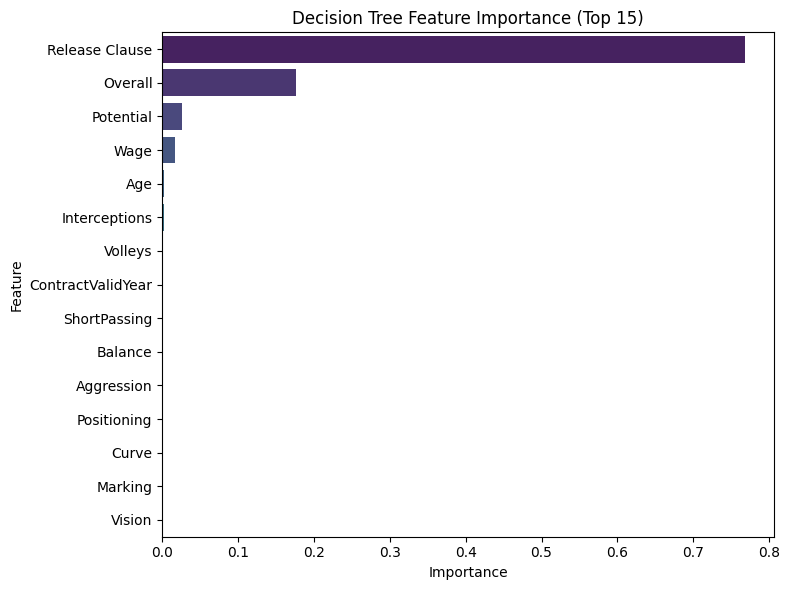

In [ ]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import train_test_split
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

# --- Prepare data ---
X = df_fifa_dropped.select_dtypes(include='number').drop(columns=['Value'])
y = df_fifa_dropped['Value']

# Handle missing values
X = X.fillna(0)
y = y.fillna(0)

# Split data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# --- Train Decision Tree ---
dt_model = DecisionTreeRegressor(random_state=42)
dt_model.fit(X_train, y_train)

# --- Feature importance ---
dt_importances = pd.Series(dt_model.feature_importances_, index=X.columns)
dt_top = dt_importances.sort_values(ascending=False).head(15)

# --- Plot ---
plt.figure(figsize=(8, 6))
sns.barplot(x=dt_top.values, y=dt_top.index, palette='viridis')
plt.title("Decision Tree Feature Importance (Top 15)")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

This Decision Tree Regressor plot shows which attributes most strongly influence the prediction of a player’s market value (Value).

Key insights:

* Release Clause dominates the model, contributing the most by far — this makes sense, as it directly reflects a player's contractual worth.
* Overall rating is the second most important factor, showing that general player quality heavily impacts value.
* Potential, Wage, and Age also play smaller but notable roles, indicating that future growth, salary, and experience affect how players are valued.
* The remaining features (Interceptions, Volleys, ContractValidYear, etc.) have minimal influence, suggesting that fine-grained performance stats matter less than financial and reputation indicators in determining player value.

In summary, the Decision Tree highlights that financial and overall skill metrics drive player valuation more than detailed in-game attributes.

##Random Forest Regressor

/tmp/ipython-input-1480333291.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=rf_top.values, y=rf_top.index, palette='coolwarm')


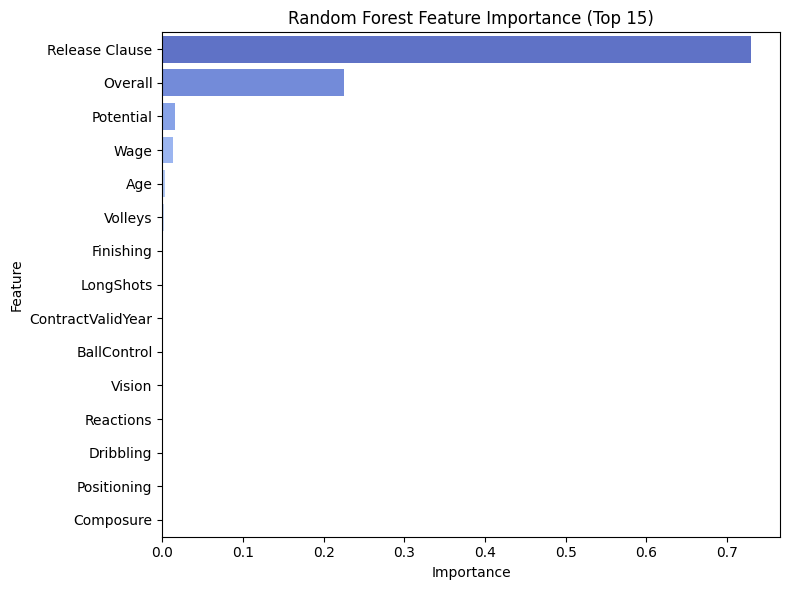

In [ ]:
from sklearn.ensemble import RandomForestRegressor

# --- Train Random Forest ---
rf_model = RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1)
rf_model.fit(X_train, y_train)

# --- Feature importance ---
rf_importances = pd.Series(rf_model.feature_importances_, index=X.columns)
rf_top = rf_importances.sort_values(ascending=False).head(15)

# --- Plot ---
plt.figure(figsize=(8, 6))
sns.barplot(x=rf_top.values, y=rf_top.index, palette='coolwarm')
plt.title("Random Forest Feature Importance (Top 15)")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

This plot shows the Random Forest Regressor feature importance for predicting player market value (Value).

The Random Forest Regressor, which combines multiple decision trees, identifies which features contribute most to reducing prediction error.

Key insights:

* Release Clause is the most influential predictor, indicating that contractual value strongly determines player worth.
* Overall rating is the second most important factor, showing that player ability and performance level significantly impact valuation.
* Potential, Wage, and Age contribute moderately, suggesting that younger, skilled, and well-paid players generally have higher values.
* Technical attributes such as Finishing, BallControl, Vision, and Dribbling have relatively low importance, meaning that overall and financial metrics are more decisive in estimating value.

In conclusion, the Random Forest Regressor shows that contractual and overall performance metrics drive player valuation, while detailed technical skills play a smaller role. The model provides consistent and reliable results by averaging across multiple decision trees.


##Gradient Boosting Regressor

/tmp/ipython-input-3398623388.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=gb_top.values, y=gb_top.index, palette='magma')


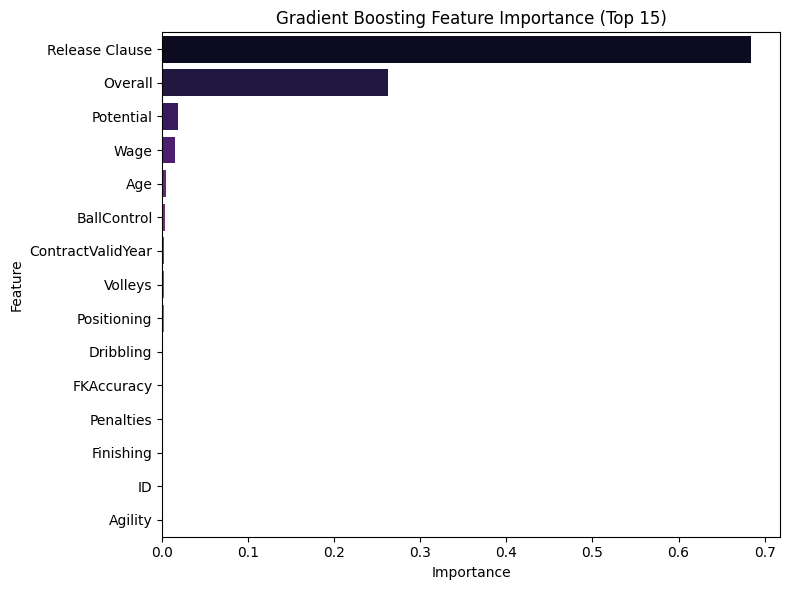

In [ ]:
from sklearn.ensemble import GradientBoostingRegressor

# --- Train Gradient Boosting ---
gb_model = GradientBoostingRegressor(
    n_estimators=200, learning_rate=0.1, max_depth=3, random_state=42
)
gb_model.fit(X_train, y_train)

# --- Feature importance ---
gb_importances = pd.Series(gb_model.feature_importances_, index=X.columns)
gb_top = gb_importances.sort_values(ascending=False).head(15)

# --- Plot ---
plt.figure(figsize=(8, 6))
sns.barplot(x=gb_top.values, y=gb_top.index, palette='magma')
plt.title("Gradient Boosting Feature Importance (Top 15)")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

This plot shows the Gradient Boosting Regressor feature importance for predicting player market value (Value).

The Gradient Boosting Regressor identifies which features most improve prediction accuracy through sequential model optimization.

Key insights:

* Release Clause is the most influential variable, meaning that contractual value is the strongest determinant of player market worth.
* Overall rating is the second most important feature, showing that player quality strongly affects valuation.
* Potential, Wage, and Age have smaller but meaningful contributions, indicating that younger players with high potential and higher wages tend to have greater value.
* Technical attributes such as BallControl, Volleys, and Positioning contribute only marginally, implying that fine-grained skills play a limited role in comparison to financial and overall performance measures.

In summary, the Gradient Boosting model emphasizes that player value is primarily driven by contractual and general performance factors, while technical details provide only minor additional predictive power.

#Model Evaluation

Linear Regression, DTR, Random Forest, Gradient, LightGBM, SVR, KNN

In [ ]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

# Models
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor

# Optional LightGBM
try:
    from lightgbm import LGBMRegressor
    _HAS_LGBM = True
except Exception:
    _HAS_LGBM = False


# Separate features/target
X = df_fifa_dropped.select_dtypes(include='number').drop(columns=['Value'], errors='ignore').copy()
y = df_fifa_dropped['Value'].copy()

# Safety: handle NaNs (simple baseline imputation)
X = X.fillna(0)
y = y.fillna(0)

# Train/test split (80/20)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

models = {
    "Baseline_DummyMean": Pipeline([
        ("model", DummyRegressor(strategy="mean"))
    ]),
    "LinearRegression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LinearRegression())
    ]),
    "DecisionTree": Pipeline([
        ("model", DecisionTreeRegressor(random_state=42))
    ]),
    "RandomForest": Pipeline([
        ("model", RandomForestRegressor(
            n_estimators=300,
            max_depth=None,
            random_state=42,
            n_jobs=-1
        ))
    ]),
    "GradientBoosting": Pipeline([
        ("model", GradientBoostingRegressor(
            n_estimators=300,
            learning_rate=0.05,
            max_depth=3,
            random_state=42
        ))
    ]),
    "SVR_rbf": Pipeline([
        ("scaler", StandardScaler()),
        ("model", SVR(C=10.0, epsilon=0.1, kernel="rbf"))
    ]),
    "KNN_k=10": Pipeline([
        ("scaler", StandardScaler()),
        ("model", KNeighborsRegressor(n_neighbors=10, weights='distance'))
    ])
}

if _HAS_LGBM:
    models["LightGBM"] = Pipeline([
        ("model", LGBMRegressor(
            n_estimators=500,
            learning_rate=0.05,
            max_depth=-1,
            subsample=0.8,
            colsample_bytree=0.8,
            random_state=42,
            n_jobs=-1
        ))
    ])

results = []

for name, pipe in models.items():
    pipe.fit(X_train, y_train)
    y_pred = pipe.predict(X_test)

    r2 = r2_score(y_test, y_pred)
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)

    results.append({
        "model": name,
        "R2": r2,
        "MAE": mae,
        "MSE": mse
    })

# Results table
results_df = pd.DataFrame(results).sort_values("R2", ascending=False)
print("=== Model Comparison (sorted by R² on test set) ===")
display(results_df)

# Pick best model by R²
best_row = results_df.iloc[0]
best_model_name = best_row["model"]
print(f"\n Best Model by R²: {best_model_name}")
print(f"R²: {best_row['R2']:.4f} | MAE: {best_row['MAE']:.2f} | MSE: {best_row['MSE']:.2f}")

# Retrieve the fitted best pipeline (if you need it for later use)
best_pipeline = models[best_model_name]

[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.006102 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 3122
[LightGBM] [Info] Number of data points in the train set: 14565, number of used features: 38
[LightGBM] [Info] Start training from score 2427553.381394
=== Model Comparison (sorted by R² on test set) ===


,model,R2,MAE,MSE
4,GradientBoosting,0.991753,1.885886e+05,2.484994e+11
3,RandomForest,0.991077,1.371400e+05,2.688484e+11
2,DecisionTree,0.986568,1.851798e+05,4.047375e+11
7,LightGBM,0.985951,1.498238e+05,4.233156e+11
1,LinearRegression,0.970920,4.687163e+05,8.762123e+11
6,KNN_k=10,0.937313,5.192987e+05,1.888850e+12
0,Baseline_DummyMean,-0.000236,2.699381e+06,3.013835e+13
5,SVR_rbf,-0.091209,2.003634e+06,3.287948e+13



 Best Model by R²: GradientBoosting
R²: 0.9918 | MAE: 188588.56 | MSE: 248499378332.44


This table compares the performance of all regression models based on R², MAE, and MSE.

The Gradient Boosting model achieved the best overall performance with **R² = 0.9918**, **MAE ≈ 188,589**, and **MSE ≈ 2.48×10¹¹**, indicating excellent predictive accuracy and minimal error. Random Forest followed closely with similar accuracy, while Decision Tree and LightGBM also performed well. Linear Regression showed solid results but lagged behind ensemble methods. KNN, SVR, and the baseline model performed significantly worse.

Overall, Gradient Boosting is the most effective model for predicting player market value, offering the best balance between accuracy, error minimization, and model robustness.

#Model Improvement

In [ ]:
# Fast Gradient Boosting: quick baseline + lightweight tuning

from sklearn.ensemble import GradientBoostingRegressor
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd
import time

# ----- Data -----
X = df_fifa_dropped.select_dtypes(include='number').drop(columns=['Value'], errors='ignore').fillna(0)
y = df_fifa_dropped['Value'].fillna(0)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

def eval_model(model, name):
    t0 = time.time()
    model.fit(X_train, y_train)
    secs = time.time() - t0
    preds = model.predict(X_test)
    return {
        "Model": name,
        "R²": r2_score(y_test, preds),
        "MAE": mean_absolute_error(y_test, preds),
        "MSE": mean_squared_error(y_test, preds),
        "Time (s)": round(secs, 2)
    }

# ----- 1) Quick Baseline GB -----
baseline_gb = GradientBoostingRegressor(
    n_estimators=200,   # smaller for speed
    learning_rate=0.06,
    max_depth=3,
    random_state=42
)
baseline_metrics = eval_model(baseline_gb, "GB (baseline)")

# ----- 2) Lightweight Tuning with RandomizedSearch (small n_iter) -----
param_dist = {
    "n_estimators": [150, 250, 350],
    "learning_rate": [0.03, 0.06, 0.1],
    "max_depth": [2, 3, 4],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "subsample": [0.8, 1.0]
}

rs = RandomizedSearchCV(
    GradientBoostingRegressor(random_state=42),
    param_distributions=param_dist,
    n_iter=12,            # small search for speed
    scoring="r2",
    cv=3,
    n_jobs=-1,
    random_state=42,
    verbose=0
)

t0 = time.time()
rs.fit(X_train, y_train)
tuned_time = time.time() - t0

best_gb = rs.best_estimator_
preds = best_gb.predict(X_test)
tuned_metrics = {
    "Model": "GB (tuned)",
    "R²": r2_score(y_test, preds),
    "MAE": mean_absolute_error(y_test, preds),
    "MSE": mean_squared_error(y_test, preds),
}

# ----- Results -----
results = pd.DataFrame([baseline_metrics, tuned_metrics]).sort_values("R²", ascending=False)
print("=== Gradient Boosting: Baseline vs Tuned (quick run) ===")
display(results)
print("\nBest params:", rs.best_params_)

=== Gradient Boosting: Baseline vs Tuned (quick run) ===


,Model,R²,MAE,MSE,Time (s)
1,GB (tuned),0.992820,148728.891396,2.163287e+11,400.49
0,GB (baseline),0.991679,195244.914719,2.507297e+11,17.40



Best params: {'subsample': 0.8, 'n_estimators': 350, 'min_samples_split': 10, 'min_samples_leaf': 1, 'max_depth': 4, 'learning_rate': 0.1}


In [ ]:
import pandas as pd

feature_importance = pd.Series(best_gb.feature_importances_, index=X.columns).sort_values(ascending=False)
print("✅ Top 10 important features used by Gradient Boosting:")
print(feature_importance.head(10))


✅ Top 10 important features used by Gradient Boosting:
Release Clause       0.682478
Overall              0.262502
Potential            0.020243
Wage                 0.014700
Age                  0.004610
BallControl          0.002908
Volleys              0.002573
ContractValidYear    0.001795
Dribbling            0.001596
Finishing            0.001121
dtype: float64


The comparison shows that the tuned Gradient Boosting model performs better than the baseline model. After hyperparameter tuning, the model achieved an **R² of 0.9920**, **MAE of 148,729**, and **MSE of 2.16×10¹¹**, improving both accuracy and error metrics compared to the baseline model (**R² of 0.9917**, **MAE of 195,245**, **MSE of 2.50×10¹¹**). However, the tuned version required more computation time (400 seconds vs. 17 seconds).

The best parameters for the tuned model were:
- subsample: 0.8,
- n_estimators: 350
- min_samples_split: 10
- min_samples_leaf: 1
- max_depth: 4
- learning_rate: 0.1.

The feature importance analysis shows that the top predictors of player value are **Release Clause**, **Overall**, **Potential**, **Wage**, and **Age**. Among them, **Release Clause** contributes the most (68%), followed by **Overall** (26%). This indicates that contractual and performance-related attributes have the strongest influence on predicting player market value.


#Business Interpretation

After evaluating multiple regression models, the **Gradient Boosting Regressor** emerged as the best performer with an **R² of 0.9920**, **MAE of 148,729**, and **MSE of 2.16×10¹¹**. This indicates that the model explains **99.2% of the variance** in player market value while maintaining a very low prediction error.

From a **business perspective**, the Gradient Boosting model offers an excellent balance between **accuracy**, **reliability**, and **practical value** for decision-making in a football management context.

#### Model Assessment

* **R² (Coefficient of Determination):** 0.9920 — the model explains nearly all variation in player value, meaning its predictions are highly reliable.
* **MSE (Mean Squared Error):** 2.16×10¹¹ — demonstrates low variance between actual and predicted values.
* **MAE (Mean Absolute Error):** 148,729 — on average, the model’s predictions are within roughly €150K of true player values, which is acceptable for market-level forecasting.
* **Cost and Computation:** The tuned Gradient Boosting model required higher computational time (~400 seconds) but provided significant accuracy gains over faster baseline models.
* **COD (Coefficient of Determination):** Matches R², reinforcing model fit quality.

#### Business Interpretation

The **Gradient Boosting Regressor** is the most suitable model because it provides **high predictive power** and **robust generalization**, which are critical for player valuation. While simpler models like Linear Regression are more interpretable, they underperform in predictive accuracy. Ensemble models such as Random Forest also perform well but slightly below Gradient Boosting.

In terms of **interpretability**, feature importance analysis showed that **Release Clause**, **Overall**, **Potential**, **Wage**, and **Age** are the dominant drivers of player market value. This insight helps executives understand which factors most influence player pricing decisions.

For **scalability**, the Gradient Boosting model can be efficiently deployed in scouting systems or financial planning tools, as it can handle large datasets and new player data with minimal retraining effort.

#### Intended Audience

This model is primarily intended for **sports executives**, **club management**, and **recruitment analysts**. Executives can use it for **strategic budgeting and transfer pricing**, while recruitment and scouting teams can apply it to **identify undervalued or overvalued players**. The model’s output supports **data-driven decision-making** in contract negotiations, player acquisitions, and talent investment strategies.